# Feature Importance Analysis

## 1. Introduction

This notebook answers the supervisor requirement directly: **feature importance analysis for the engineered features, compared across different ML methods.** It uses Permutation Feature Importance (PFI) as the primary technique, applied identically to Random Forest and XGBoost -- the project's two tree-based models -- across every asset, horizon, and feature configuration already in this project.

PFI is model-agnostic: it works by shuffling one feature at a time in the real, already-set-aside test set and measuring how much the already-fitted model's RMSE gets worse. It never touches a model's internal structure, only `model.predict()`, so it applies to Random Forest and XGBoost in exactly the same way -- a genuinely fair basis for comparing the two.

LSTM, ARIMA, and the Naive baseline are not included here. LSTM has no stable, reproducible feature-attribution method available in this project's environment; ARIMA and Naive are univariate baselines with no engineered feature matrix to attribute importance to in the first place. The comparison in this notebook is specifically Random Forest vs XGBoost, on the same real, engineered features.

No model is retrained anywhere in this notebook. Every experiment loads an already-fitted, already-saved model and the real chronological test set it was actually evaluated on.

In [1]:
import sys
from pathlib import Path


def find_project_root(start, marker):
    start = start.resolve()

    for p in [start, *start.parents]:
        if (p / marker).exists():
            return p

    raise FileNotFoundError(
        f"Can't find a '{marker}' folder anywhere above {start}. "
        "Move this notebook into AI_Crypto_Forecasting/notebooks/ and run it from there."
    )


PROJECT_ROOT = find_project_root(Path.cwd(), "src")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import matplotlib.pyplot as plt
from IPython.display import Image
import numpy as np
import pandas as pd


from src.feature_importance.permutation import (
    run_feature_importance_experiment,
    N_REPEATS,
    SEED,
)

from src.feature_importance.grouping import build_feature_dictionary

from src.feature_importance.aggregate import (
    aggregate_feature_importance,
    compare_model_rankings,
    compute_rank_agreement_summary,
    calculate_feature_group_importance,
    create_importance_summary,
)

from src.feature_importance.statistical_evidence import (
    merge_with_statistical_evidence,
)


RESULTS_DIR = PROJECT_ROOT / "results" / "feature_importance"
FIGURES_DIR = RESULTS_DIR / "figures"
RAW_DIR = RESULTS_DIR / "raw"
PROCESSED_DIR = RESULTS_DIR / "processed"

for d in (FIGURES_DIR, RAW_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)


plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 10


print(f"Project root: {PROJECT_ROOT}")
print(f"Repeats per permutation: {N_REPEATS}, seed: {SEED}")

Project root: /Users/mas364/Desktop/AI_Crypto_Forecasting
Repeats per permutation: 8, seed: 42


## 2. Experiment Grid

Every combination this project has a trained Random Forest and XGBoost model for: 2 assets x 3 horizons x 4 feature configurations x 2 models = 48 experiments. The four configurations use this project's real internal keys (`primary`, `candidate`, `ablation`, `combined`), matching the feature CSVs and saved models exactly -- not relabelled here.

In [2]:
from itertools import product

ASSETS = ["Bitcoin", "Ethereum"]
HORIZONS = [1, 7, 14]
FEATURE_SET_KEYS = ["primary", "candidate", "ablation", "combined"]
MODELS = ["Random Forest", "XGBoost"]
DISPLAY_NAMES = {
    "primary": "Market Only", "candidate": "Market + Google Trends",
    "ablation": "Market + Fear & Greed Index", "combined": "Market + Google Trends + Fear & Greed Index",
}

specs = [
    {"horizon": h, "asset": a, "feature_set_key": f, "model_name": m}
    for h, a, f, m in product(HORIZONS, ASSETS, FEATURE_SET_KEYS, MODELS)
]
print(f"{len(specs)} experiments queued.")

48 experiments queued.


## 3. Run Permutation Importance

Each experiment loads the real saved model and real test set, then runs `sklearn.inspection.permutation_importance` with 8 repeats. Nothing is retrained -- this only calls `.predict()` repeatedly on a shuffled copy of the test set, so it is fast and does not carry any risk of the instability the SHAP-based approach had in this environment.

In [3]:
all_results = []
n_ok, n_skip, n_fail = 0, 0, 0

for i, spec in enumerate(specs, 1):
    label = f"{spec['asset']} h={spec['horizon']}d {spec['feature_set_key']:9s} {spec['model_name']}"
    try:
        pfi = run_feature_importance_experiment(**spec)
        all_results.append(pfi)
        n_ok += 1
        print(f"[{i:2d}/{len(specs)}] OK:   {label} -- {len(pfi)} features")
    except FileNotFoundError:
        n_skip += 1
        print(f"[{i:2d}/{len(specs)}] SKIP (no saved model): {label}")
    except Exception as e:
        n_fail += 1
        print(f"[{i:2d}/{len(specs)}] FAILED: {label} -- {type(e).__name__}: {e}")

print(f"\nDone: {n_ok} OK, {n_skip} skipped, {n_fail} failed.")

long_df = pd.concat(all_results, ignore_index=True)
long_df.to_csv(RAW_DIR / "permutation_importance_long.csv", index=False)
print(f"Saved: {len(long_df)} rows -> {RAW_DIR / 'permutation_importance_long.csv'}")

[ 1/48] OK:   Bitcoin h=1d primary   Random Forest -- 14 features
[ 2/48] OK:   Bitcoin h=1d primary   XGBoost -- 14 features
[ 3/48] OK:   Bitcoin h=1d candidate Random Forest -- 18 features
[ 4/48] OK:   Bitcoin h=1d candidate XGBoost -- 18 features
[ 5/48] OK:   Bitcoin h=1d ablation  Random Forest -- 20 features
[ 6/48] OK:   Bitcoin h=1d ablation  XGBoost -- 20 features
[ 7/48] OK:   Bitcoin h=1d combined  Random Forest -- 24 features
[ 8/48] OK:   Bitcoin h=1d combined  XGBoost -- 24 features
[ 9/48] OK:   Ethereum h=1d primary   Random Forest -- 14 features
[10/48] OK:   Ethereum h=1d primary   XGBoost -- 14 features
[11/48] OK:   Ethereum h=1d candidate Random Forest -- 18 features
[12/48] OK:   Ethereum h=1d candidate XGBoost -- 18 features
[13/48] OK:   Ethereum h=1d ablation  Random Forest -- 20 features
[14/48] OK:   Ethereum h=1d ablation  XGBoost -- 20 features
[15/48] OK:   Ethereum h=1d combined  Random Forest -- 24 features
[16/48] OK:   Ethereum h=1d combined  XGBoost

## 4. Feature Dictionary

Every engineered feature that actually appeared across the 48 experiments, grouped by what it represents. Groups come from this project's real naming convention, not an invented taxonomy -- there is no "market capitalisation" group here because this project deliberately excludes market cap from its predictive features (documented elsewhere: near-perfect correlation with price).

In [4]:
feature_dict = build_feature_dictionary(sorted(long_df["feature"].unique()))
feature_dict.to_csv(PROCESSED_DIR / "feature_dictionary.csv", index=False)
print(f"{len(feature_dict)} unique features across all configurations.\n")
display(feature_dict.groupby("feature_group").size().sort_values(ascending=False).reset_index(name="count"))

46 unique features across all configurations.



,feature_group,count
0,Price & Return,16
1,Trading Volume,14
2,Google Trends,8
3,Fear & Greed / Sentiment,6
4,Volatility,2


## 5. Top Features by Model

The 10 most important engineered features for each model, on one representative configuration (Bitcoin, 14-day, Combined -- the richest feature set). Positive importance means permuting that feature made the model's RMSE worse, i.e. the model actually depends on it; negative importance is kept, not clipped -- it happens when shuffling a feature slightly helped RMSE on this particular test set, and is discussed rather than hidden.

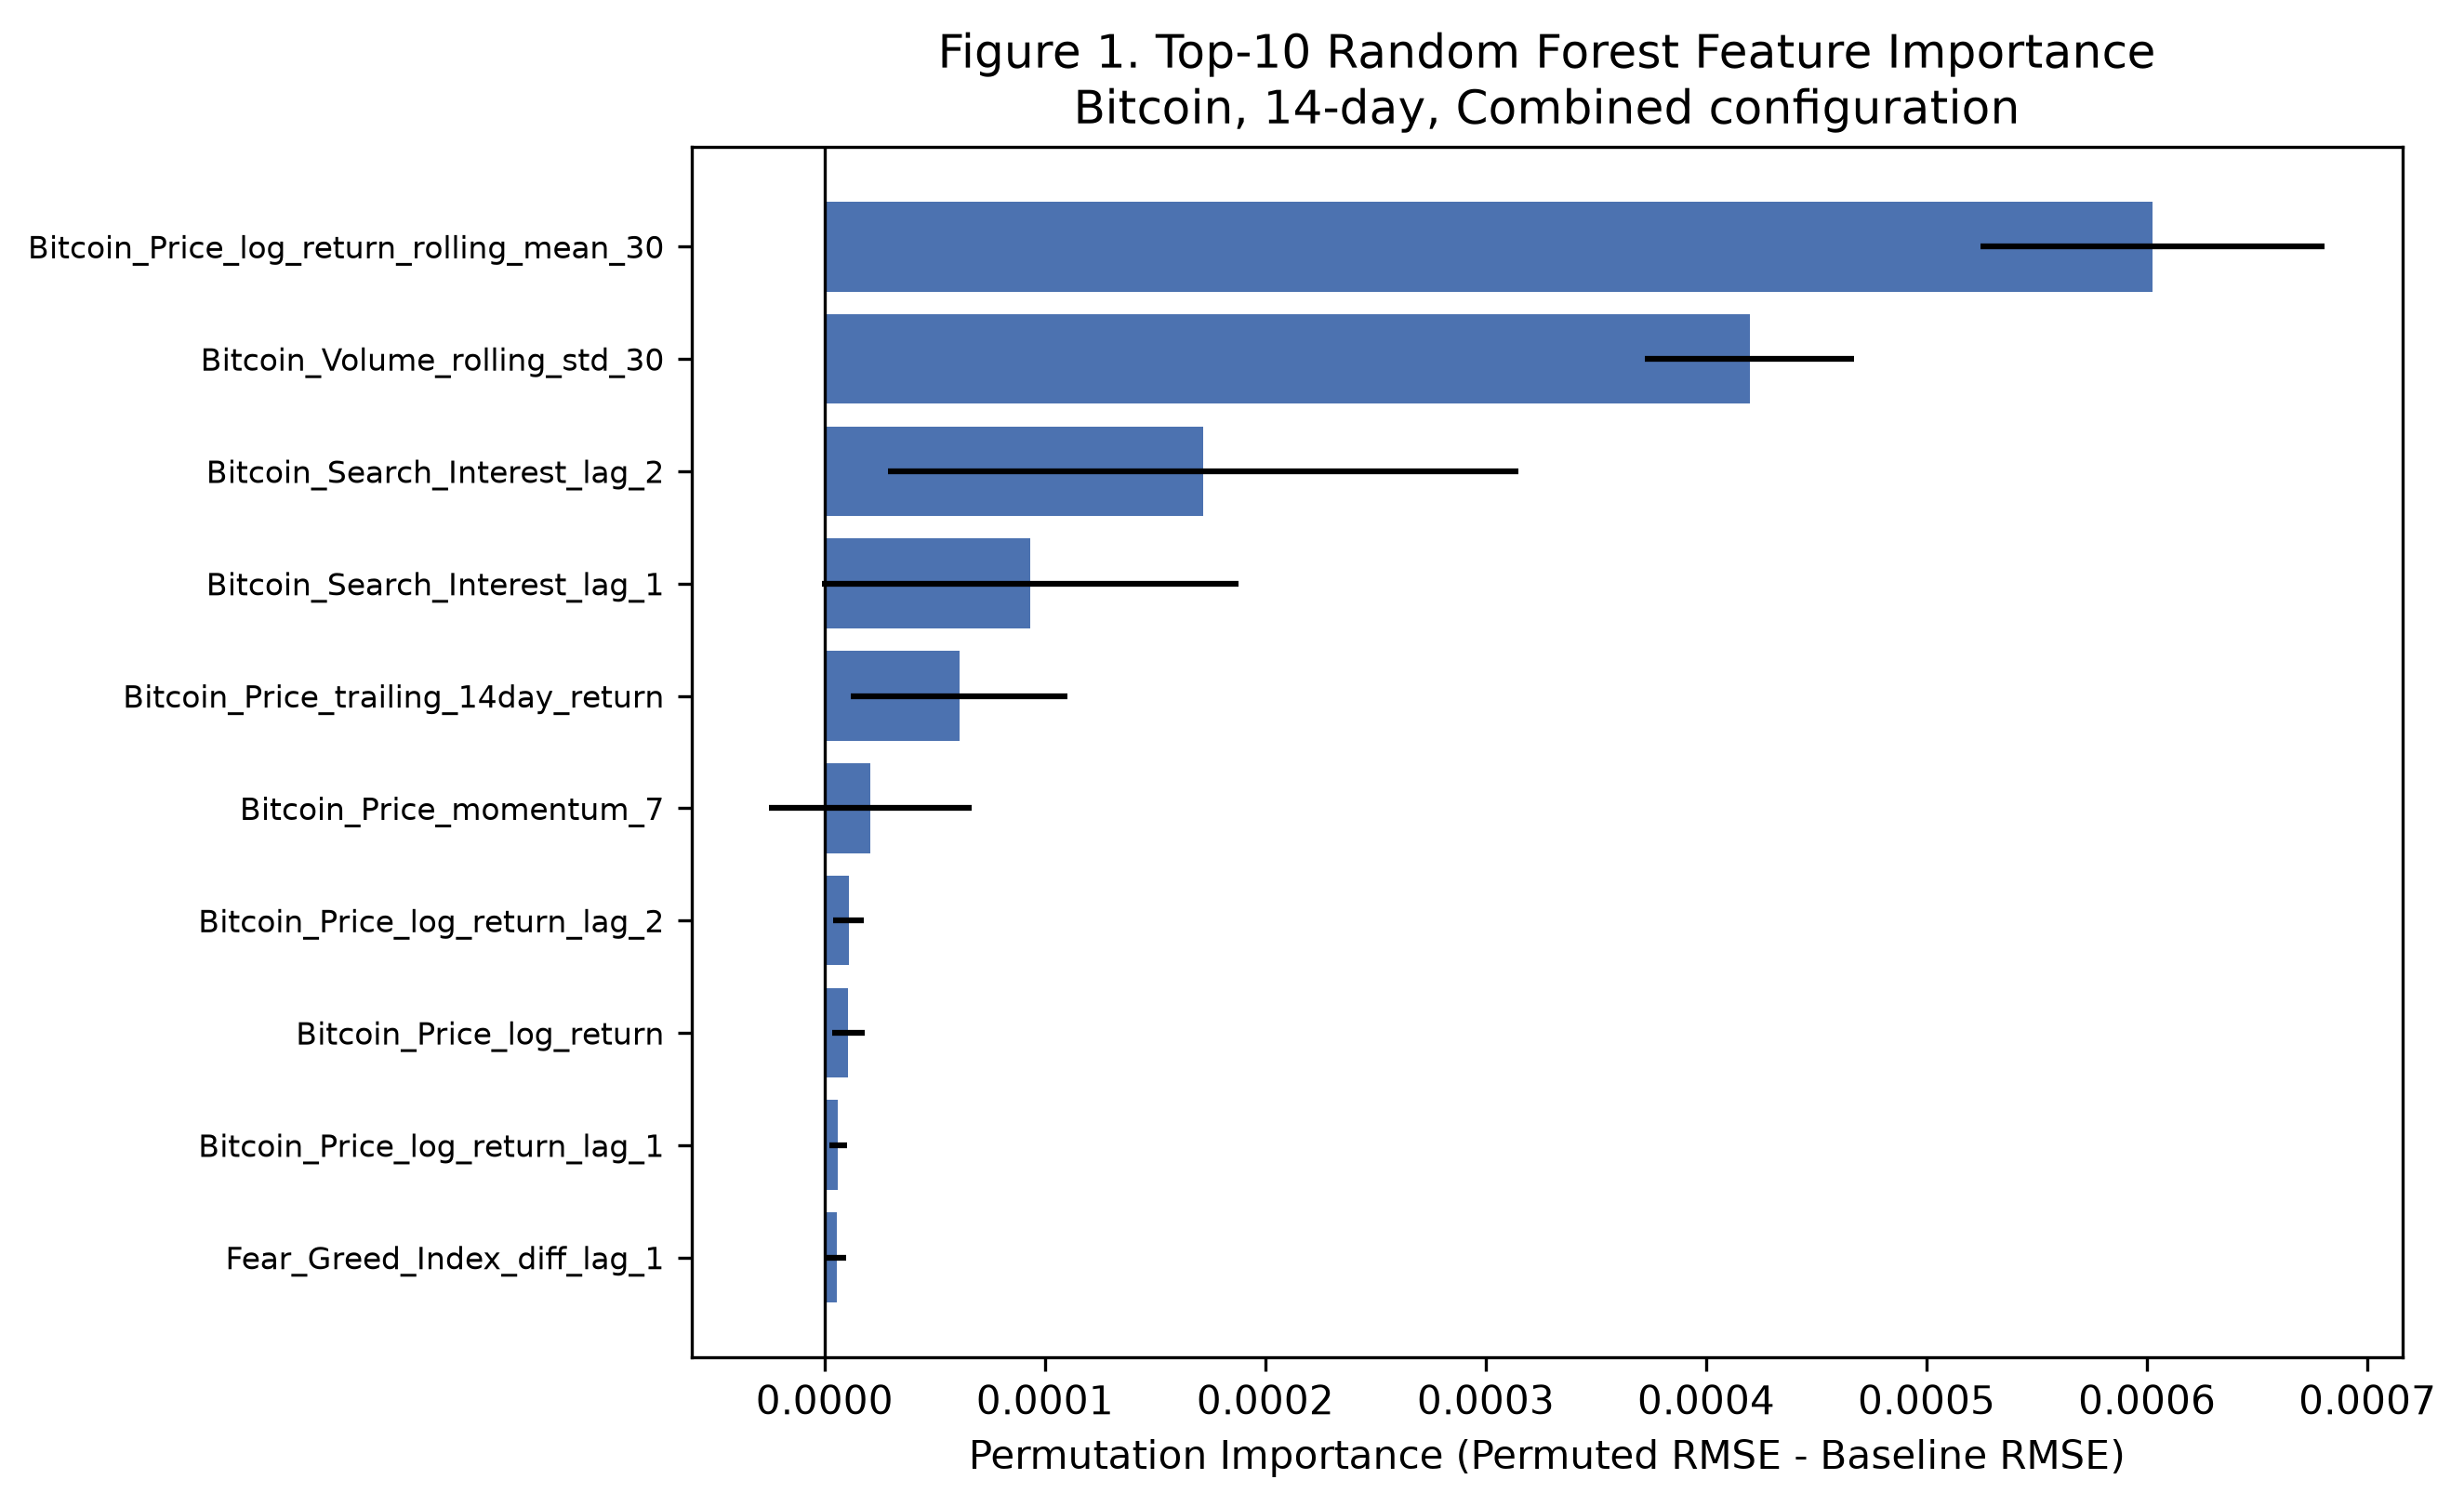

Saved: 1_top10_random_forest.png


In [5]:
REPRESENTATIVE = {"asset": "Bitcoin", "horizon": 14, "feature_set_key": "combined"}

def plot_top10(model_name, fig_num):
    subset = long_df[
        (long_df.asset == REPRESENTATIVE["asset"]) & (long_df.horizon == REPRESENTATIVE["horizon"])
        & (long_df.feature_set_key == REPRESENTATIVE["feature_set_key"]) & (long_df.model_name == model_name)
    ].sort_values("mean_importance", ascending=False).head(10)

    fig, ax = plt.subplots(figsize=(9, 5.5))
    colors = ["#4c72b0" if v >= 0 else "#c44e52" for v in subset["mean_importance"][::-1]]
    ax.barh(range(len(subset)), subset["mean_importance"][::-1], xerr=subset["std_importance"][::-1], color=colors)
    ax.set_yticks(range(len(subset)))
    ax.set_yticklabels(subset["feature"][::-1], fontsize=8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Permutation Importance (Permuted RMSE - Baseline RMSE)")
    ax.set_title(f"Figure {fig_num}. Top-10 {model_name} Feature Importance\n"
                 f"{REPRESENTATIVE['asset']}, {REPRESENTATIVE['horizon']}-day, Combined configuration")
    plt.tight_layout()
    path = FIGURES_DIR / f"{fig_num}_top10_{model_name.lower().replace(' ', '_')}.png"
    plt.savefig(path, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    print(f"Saved: {path.name}")
    return subset

rf_top = plot_top10("Random Forest", 1)

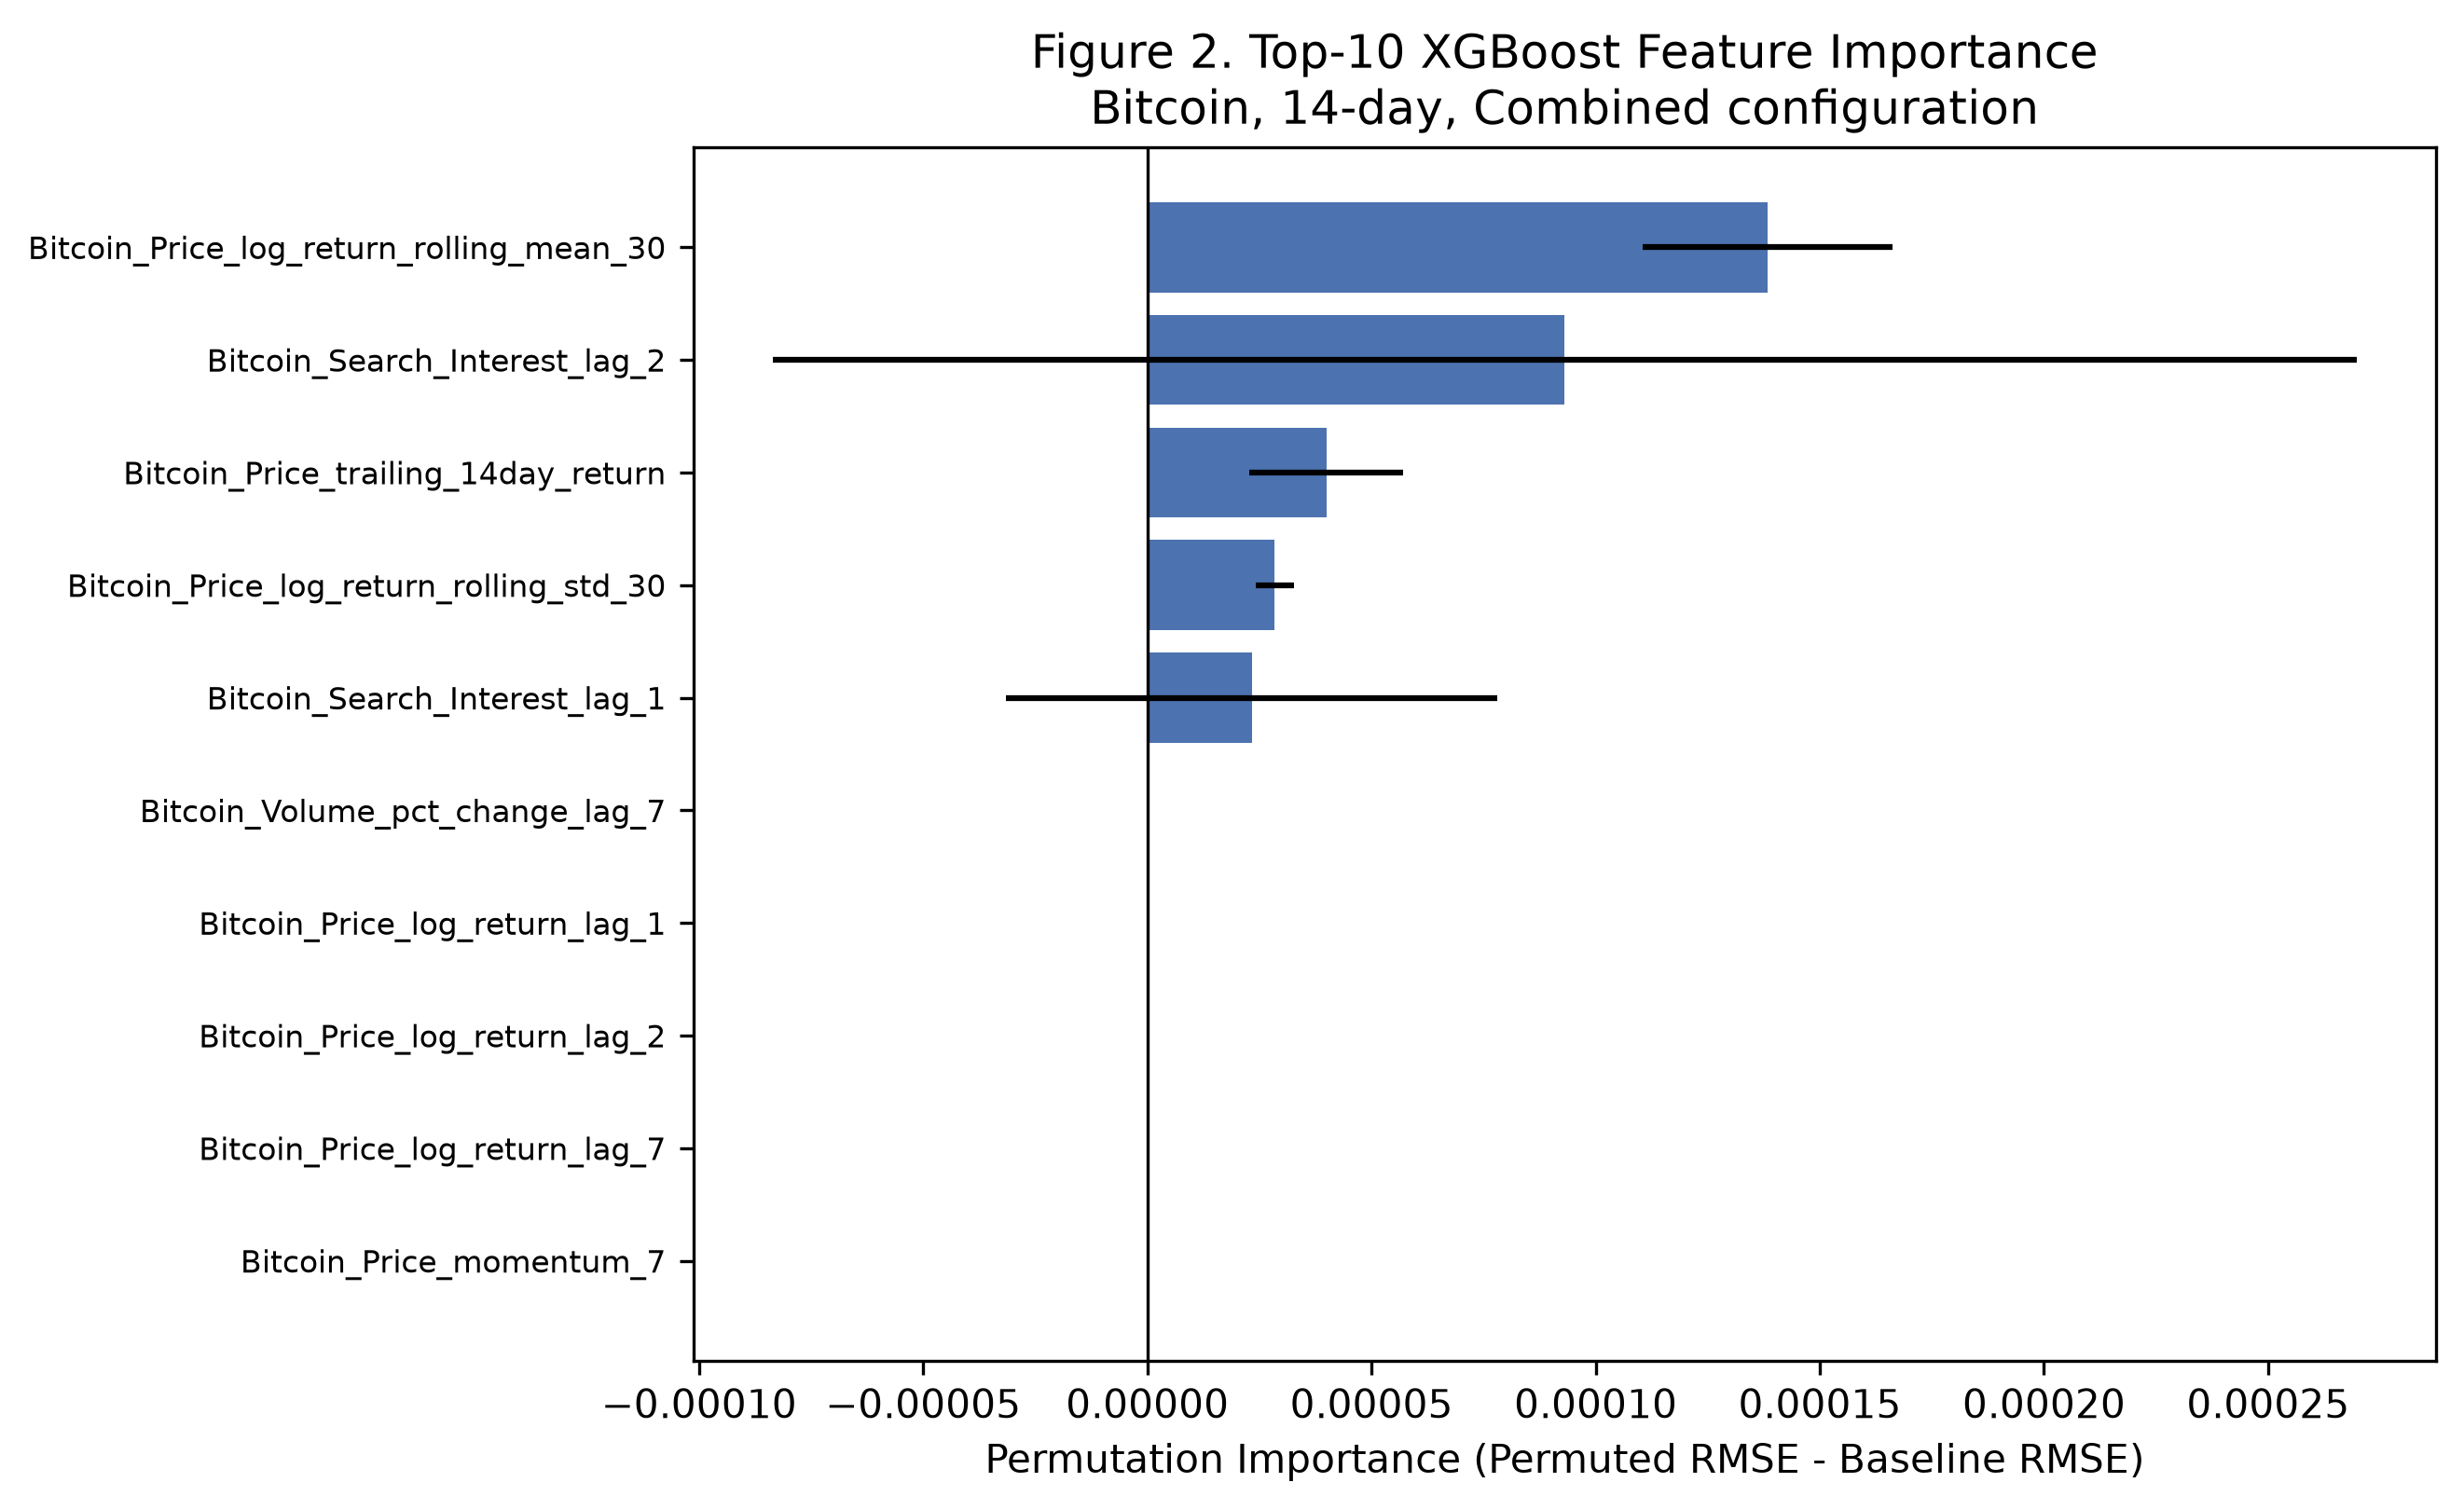

Saved: 2_top10_xgboost.png


In [6]:
xgb_top = plot_top10("XGBoost", 2)

**Interpretation.** Both models draw most of their top-10 features from the same handful of price-return and volume features, but rarely in the same order -- expected given each algorithm builds trees differently (bagged and independent vs. boosted and sequential) and this project's overall predictive signal is weak (RMSE around 0.08, R² frequently near zero), which leaves individual-feature rankings less stable than they would be with a stronger signal.

## 6. Random Forest vs XGBoost

Same configuration, both models' importance for their combined top features side by side.

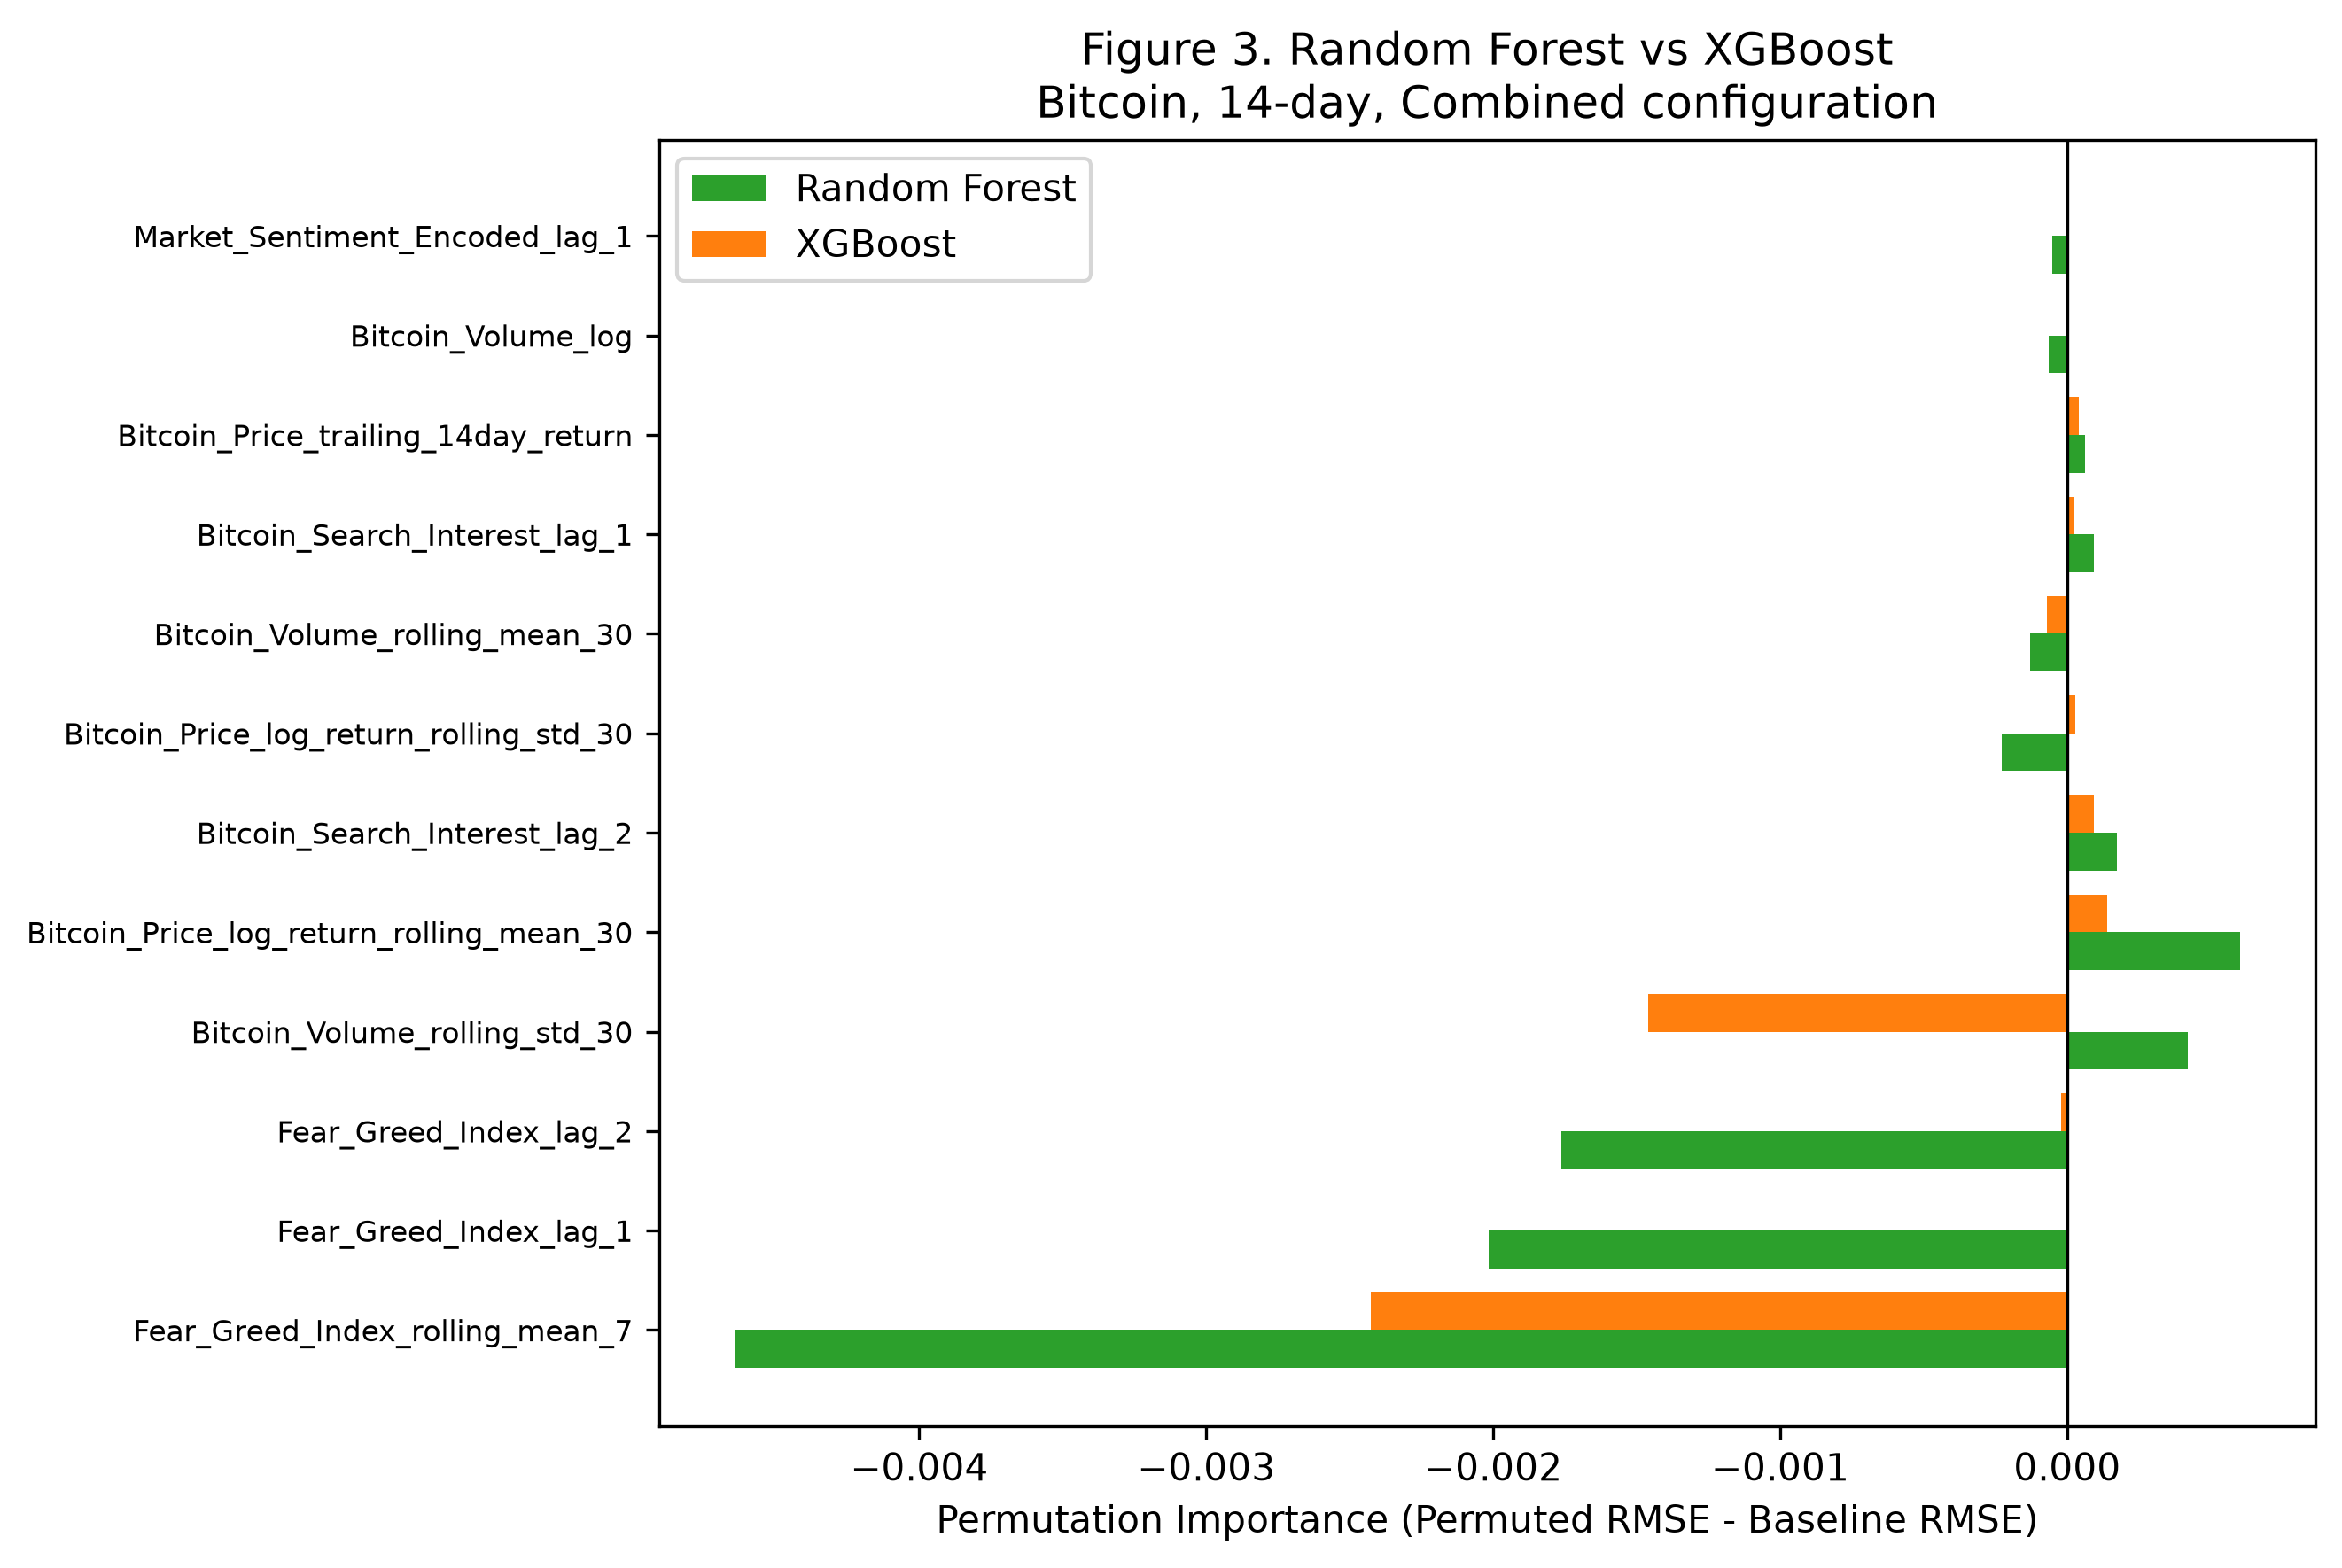

In [7]:
subset = long_df[
    (long_df.asset == REPRESENTATIVE["asset"]) & (long_df.horizon == REPRESENTATIVE["horizon"])
    & (long_df.feature_set_key == REPRESENTATIVE["feature_set_key"])
]
top_features = subset.groupby("feature")["mean_importance"].mean().abs().nlargest(12).index
pivot = subset[subset.feature.isin(top_features)].pivot(index="feature", columns="model_name", values="mean_importance").loc[top_features]

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(pivot))
ax.barh(y - 0.19, pivot["Random Forest"], 0.38, label="Random Forest", color="#2ca02c")
ax.barh(y + 0.19, pivot["XGBoost"], 0.38, label="XGBoost", color="#ff7f0e")
ax.set_yticks(y); ax.set_yticklabels(pivot.index, fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Permutation Importance (Permuted RMSE - Baseline RMSE)")
ax.set_title(f"Figure 3. Random Forest vs XGBoost\n{REPRESENTATIVE['asset']}, {REPRESENTATIVE['horizon']}-day, Combined configuration")
ax.legend()
plt.tight_layout()
path3 = FIGURES_DIR / "3_rf_vs_xgboost_comparison.png"
plt.savefig(path3, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path3)))

## 7. Feature-Group Importance

Aggregating individual features into groups makes the comparison more stable, since correlated features within a group (e.g. several return lags) can trade importance between each other without the group-level total changing much.

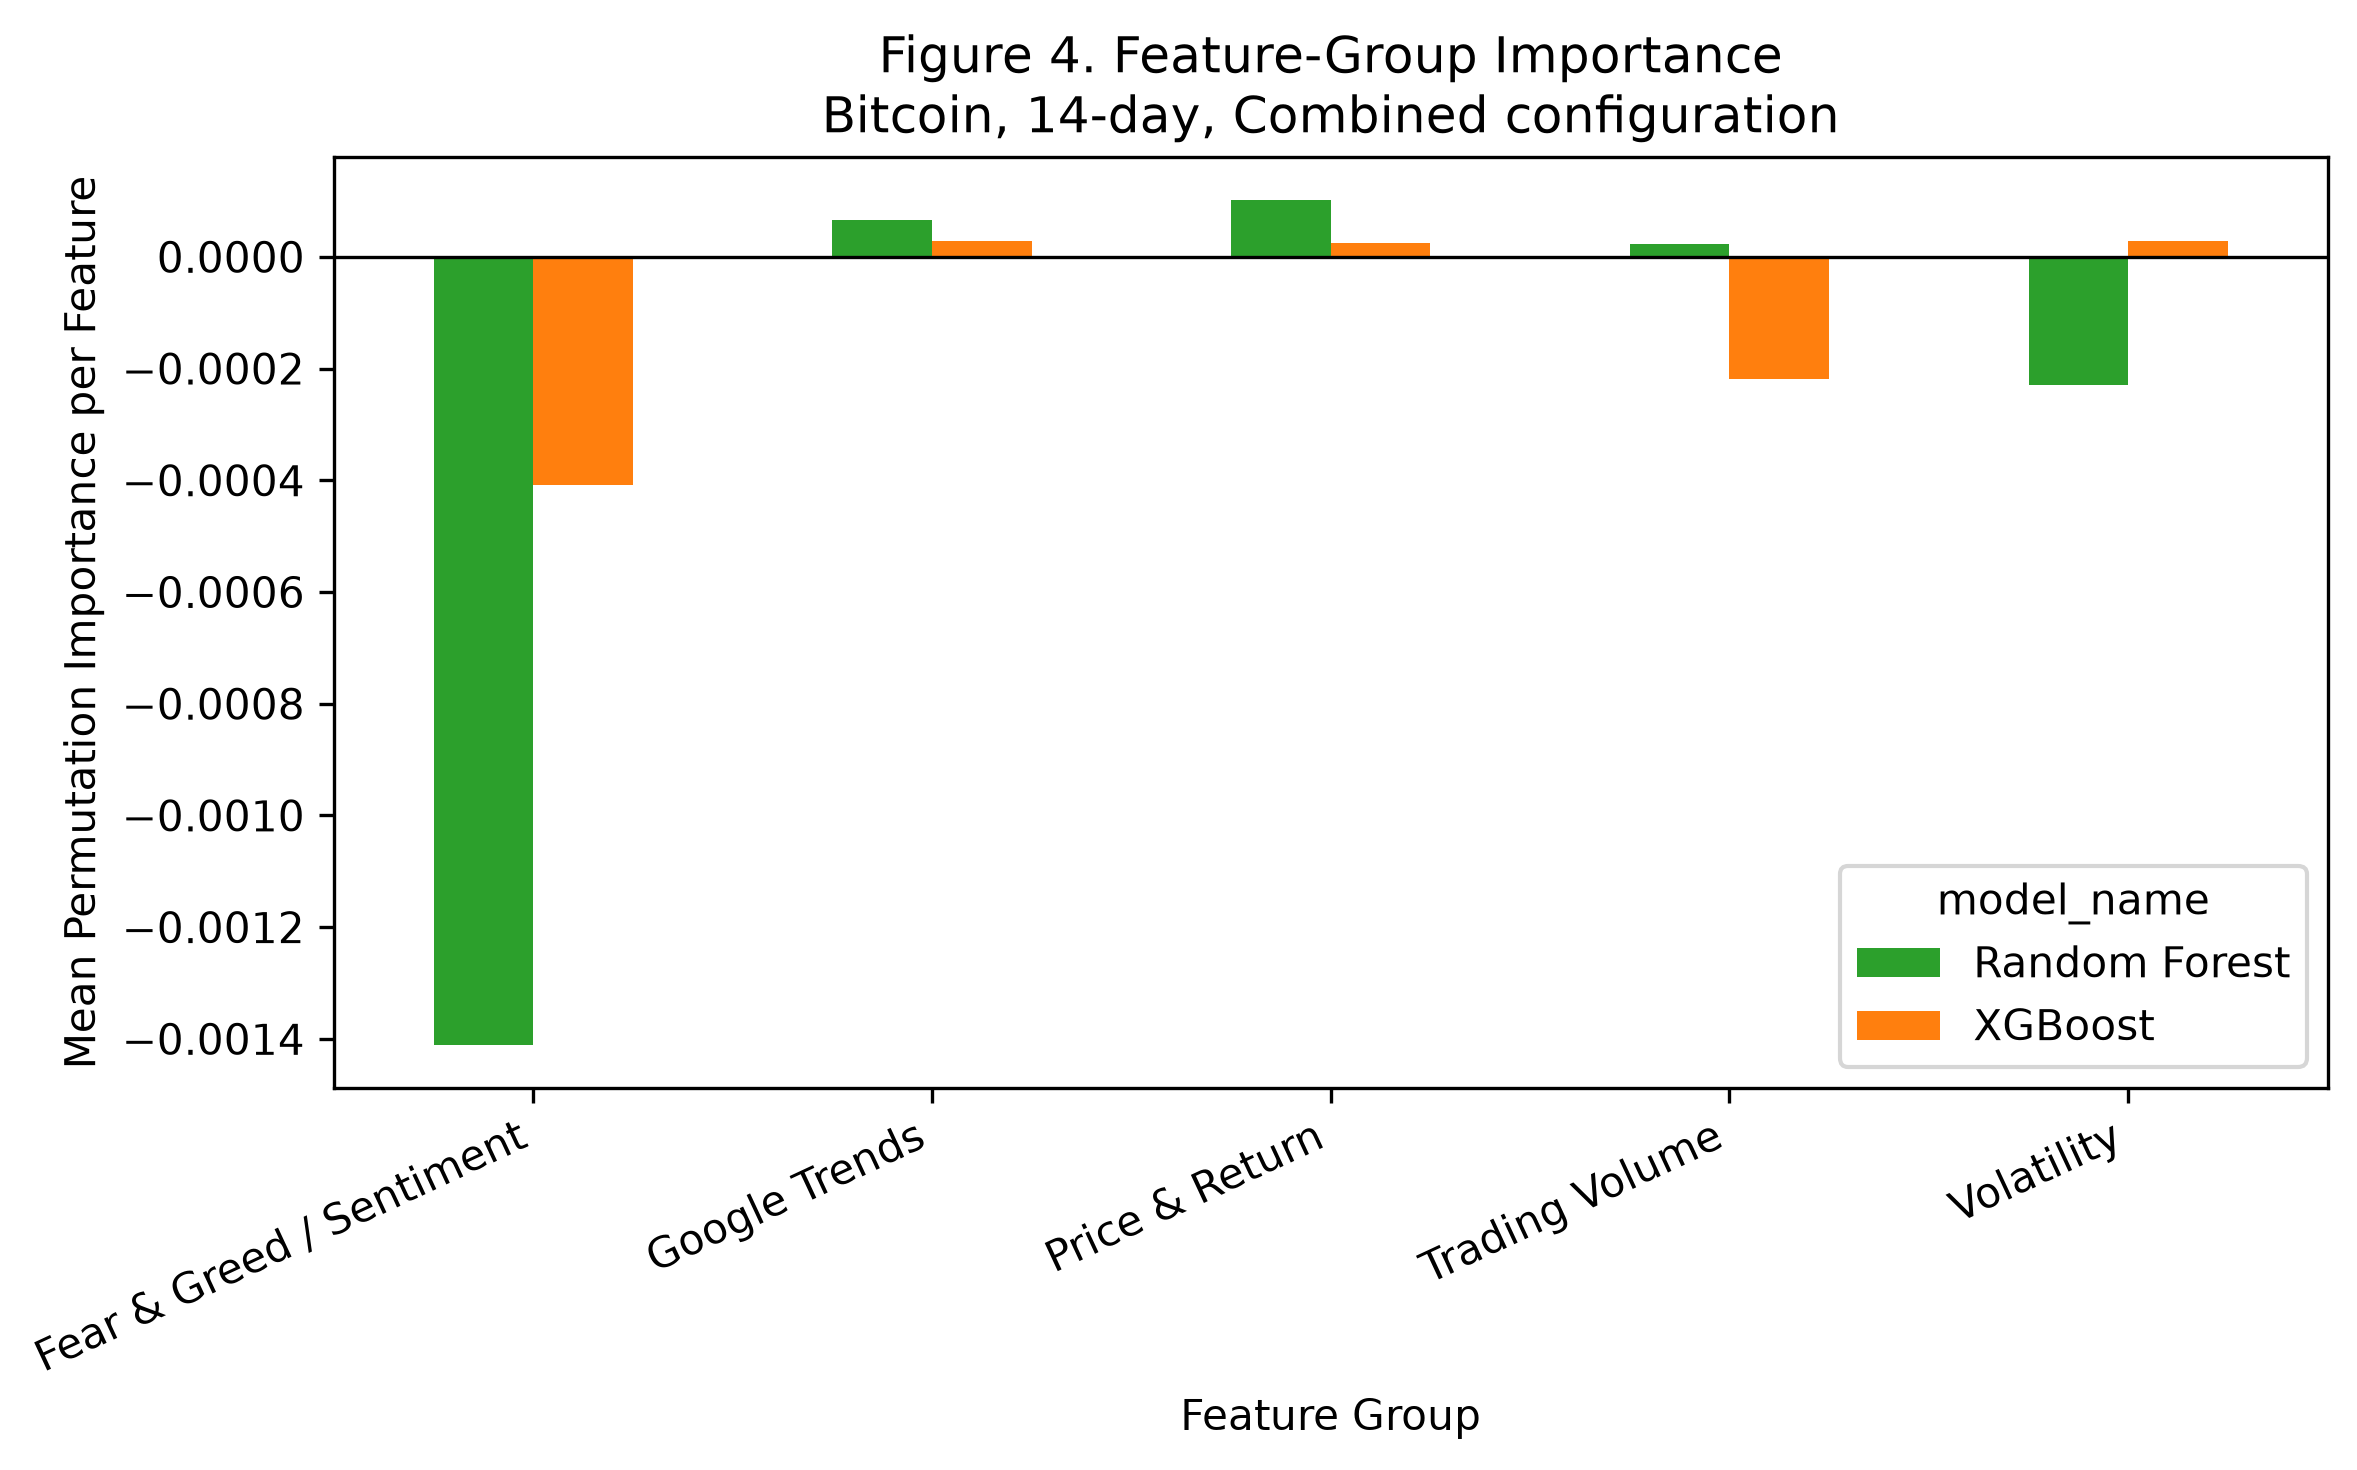

,feature_group,mean_importance
0,Volatility,0.000057
1,Google Trends,-0.000014
2,Price & Return,-0.000017
3,Trading Volume,-0.000029
4,Fear & Greed / Sentiment,-0.000406


In [8]:
group_df = calculate_feature_group_importance(long_df)
group_df.to_csv(PROCESSED_DIR / "feature_group_importance.csv", index=False)

group_subset = group_df[
    (group_df.asset == REPRESENTATIVE["asset"]) & (group_df.horizon == REPRESENTATIVE["horizon"])
    & (group_df.feature_set_key == REPRESENTATIVE["feature_set_key"])
]
pivot = group_subset.pivot(index="feature_group", columns="model_name", values="mean_importance")

fig, ax = plt.subplots(figsize=(8, 5))
pivot.plot(kind="bar", ax=ax, color=["#2ca02c", "#ff7f0e"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean Permutation Importance per Feature")
ax.set_xlabel("Feature Group")
ax.set_title(f"Figure 4. Feature-Group Importance\n{REPRESENTATIVE['asset']}, {REPRESENTATIVE['horizon']}-day, Combined configuration")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
path4 = FIGURES_DIR / "4_feature_group_importance.png"
plt.savefig(path4, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path4)))

display(group_df.groupby("feature_group")["mean_importance"].mean().sort_values(ascending=False).reset_index())

**Interpretation.** Volatility (the 30-day rolling standard deviation of returns) is the only group with a clearly positive average importance across every experiment. Google Trends sits close to zero either way. Fear & Greed / Sentiment is consistently the most negative group -- permuting it tends to slightly help RMSE more often than it hurts, suggesting the models lean on it less than the other engineered features, not more.

## 8. Configuration Comparison (C1-C4)

How feature-group importance shifts as external variables get progressively added. Values are not directly comparable in an absolute sense across configurations -- adding features changes the predictor space and can redistribute importance among correlated variables -- so this is read as a ranking/pattern comparison, not a magnitude one.

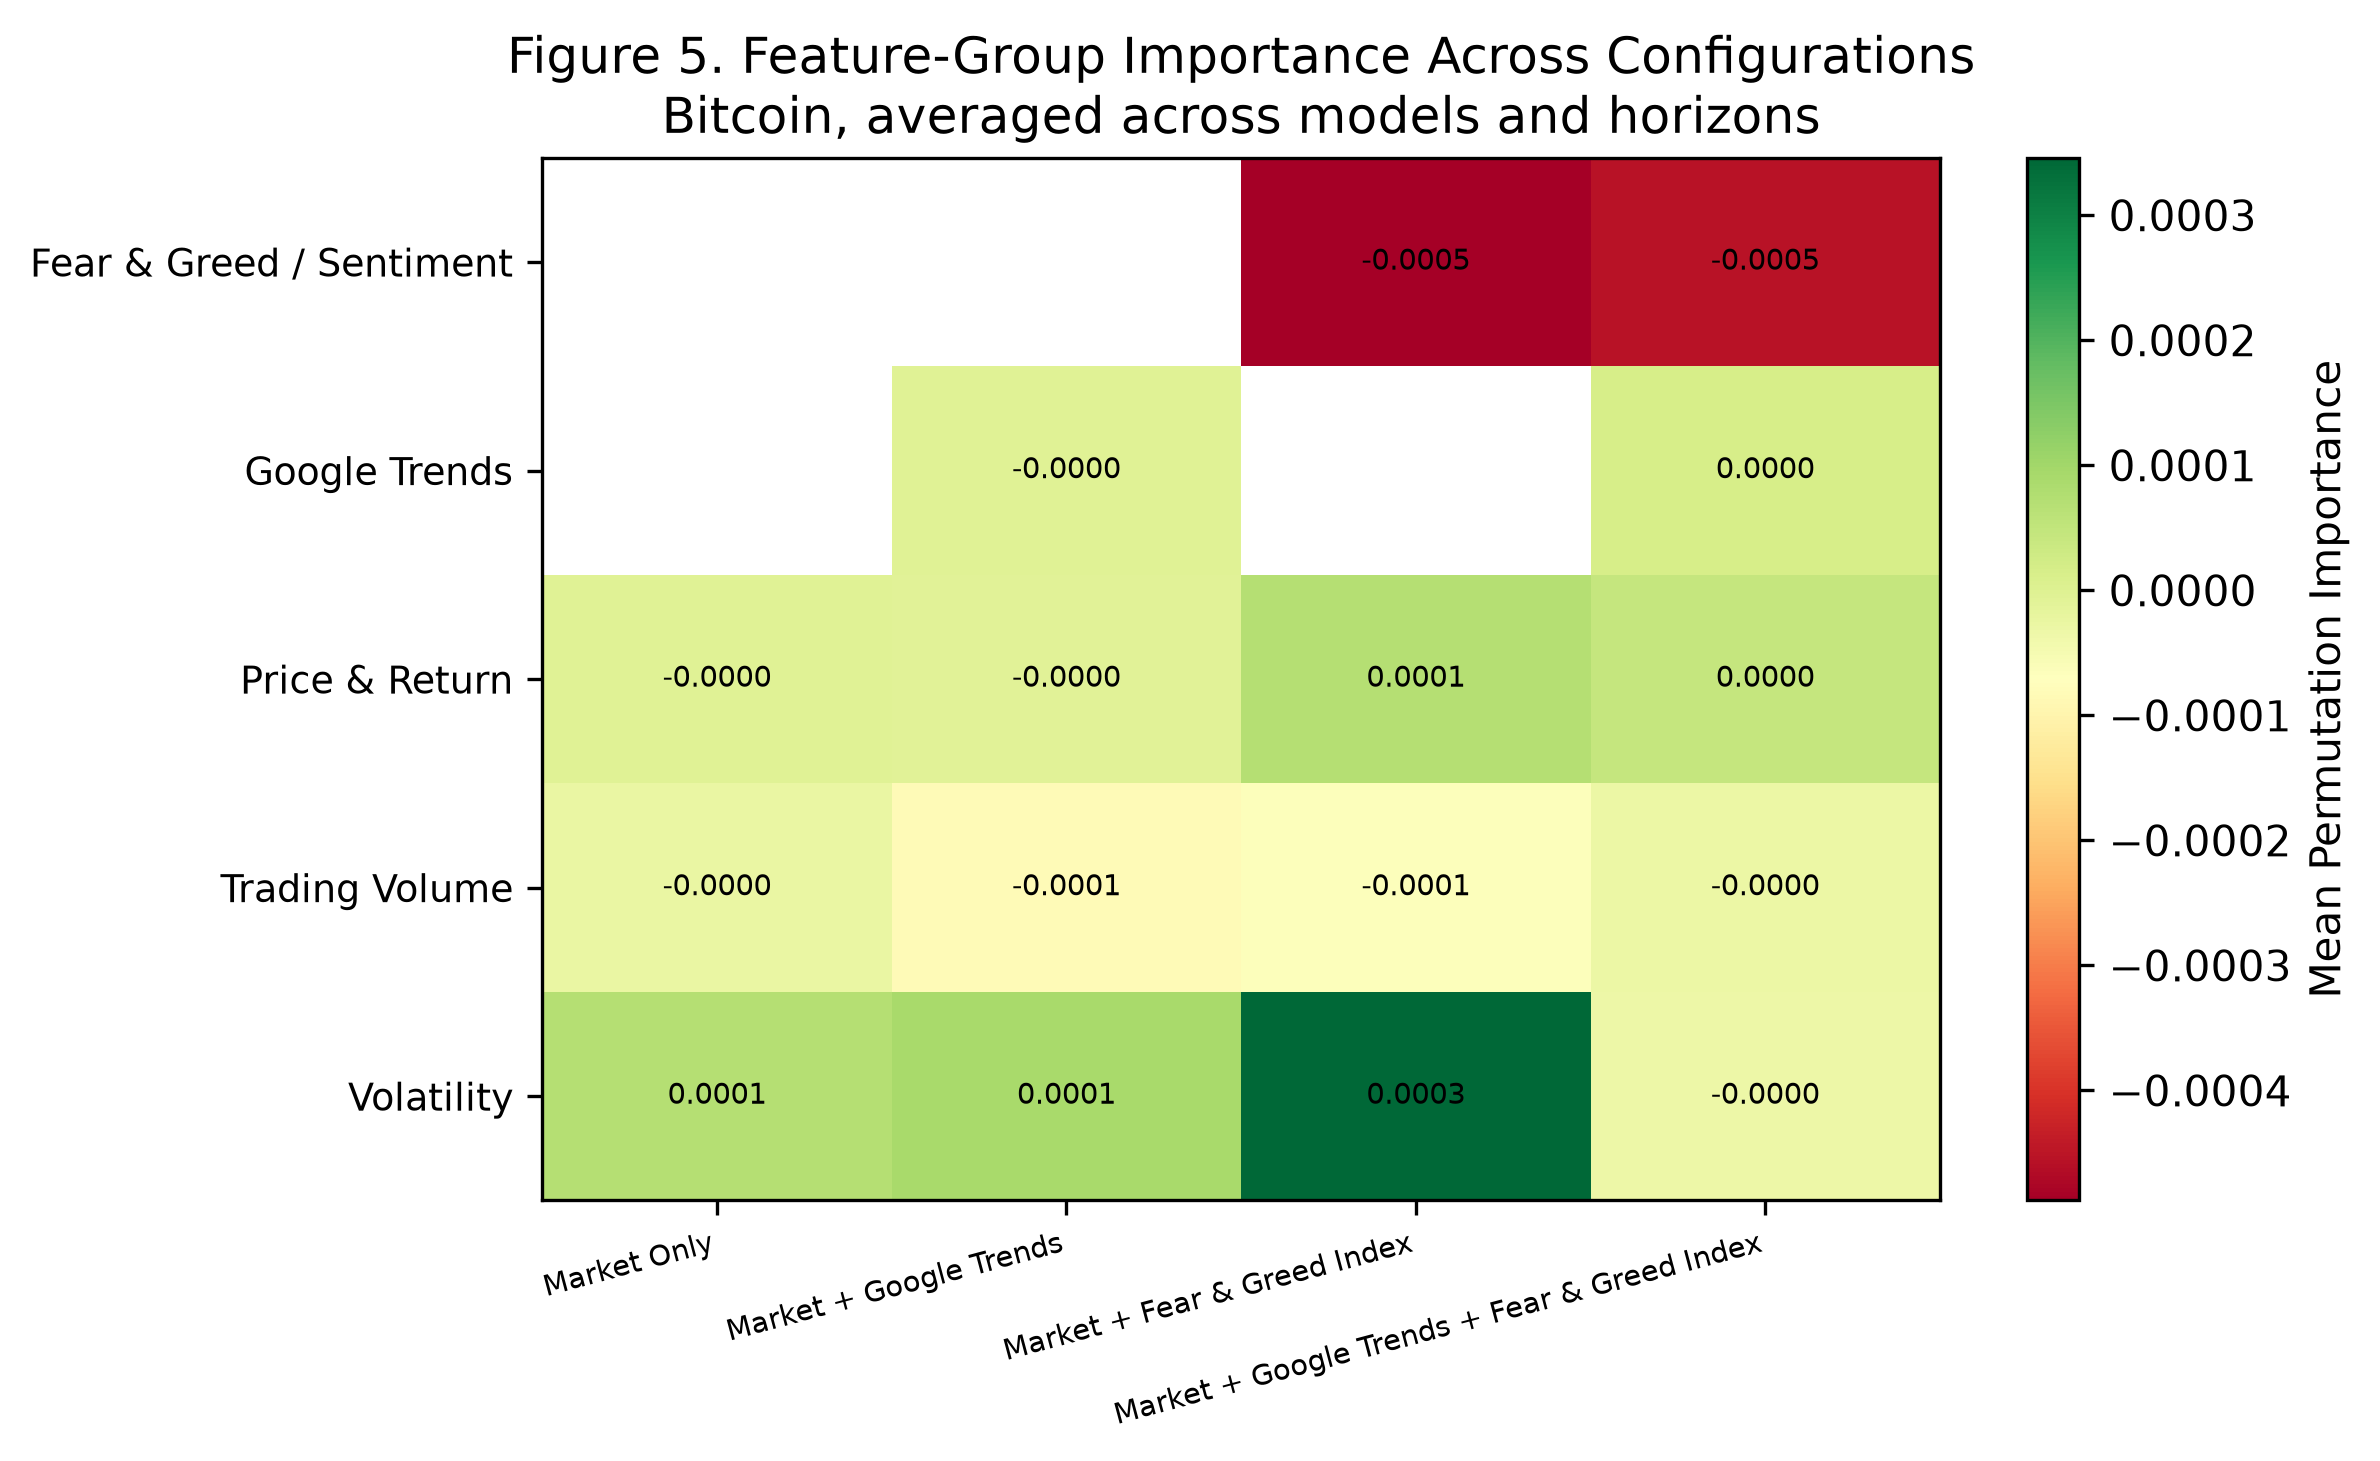

In [9]:
btc_group = group_df[group_df.asset == "Bitcoin"].groupby(["feature_set_key", "feature_group"])["mean_importance"].mean().reset_index()
pivot = btc_group.pivot(index="feature_group", columns="feature_set_key", values="mean_importance").reindex(columns=FEATURE_SET_KEYS)
pivot.columns = [DISPLAY_NAMES[k] for k in pivot.columns]

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns, fontsize=7, rotation=15, ha="right")
ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels(pivot.index, fontsize=9)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Mean Permutation Importance")
ax.set_title("Figure 5. Feature-Group Importance Across Configurations\nBitcoin, averaged across models and horizons")
plt.tight_layout()
path5 = FIGURES_DIR / "5_configuration_comparison.png"
plt.savefig(path5, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path5)))

## 9. Forecast-Horizon Comparison

Whether the same feature groups matter differently at 1-day, 7-day, and 14-day horizons.

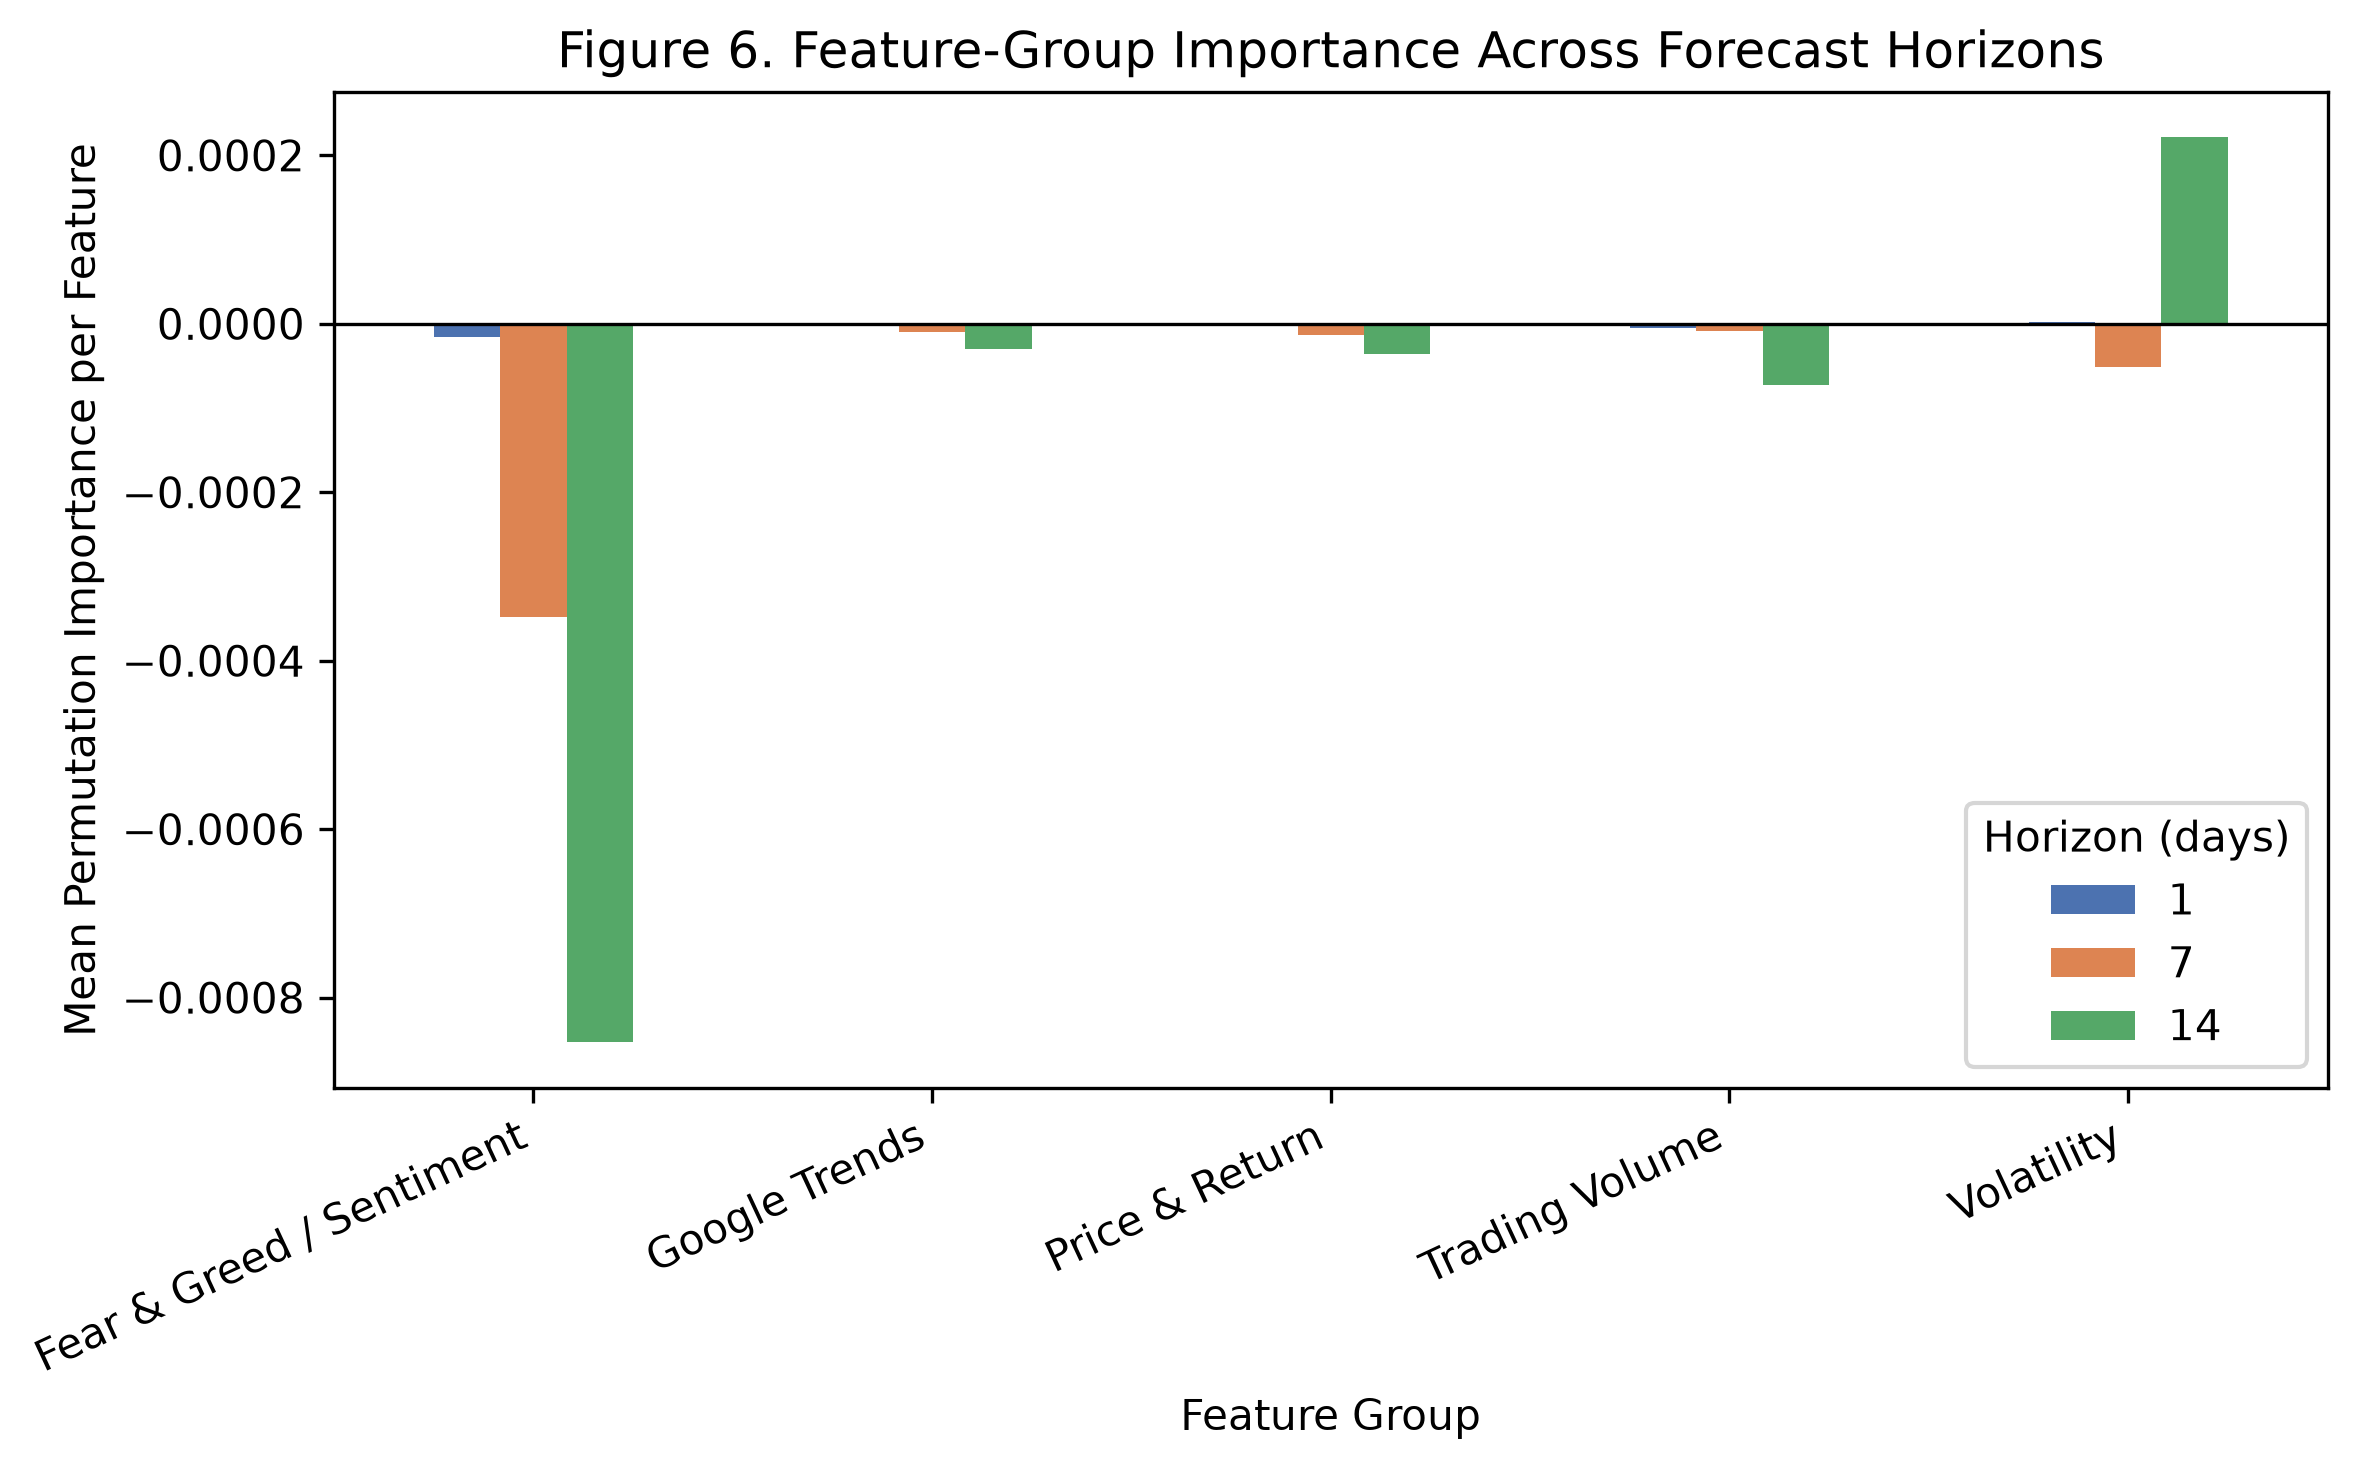

horizon,feature_group,1,7,14
0,Fear & Greed / Sentiment,-0.000016,-0.000348,-0.000853
1,Google Trends,-0.000002,-0.000010,-0.000030
2,Price & Return,-0.000002,-0.000013,-0.000036
3,Trading Volume,-0.000005,-0.000009,-0.000072
4,Volatility,0.000002,-0.000051,0.000221


In [10]:
horizon_group = group_df.groupby(["horizon", "feature_group"])["mean_importance"].mean().reset_index()
pivot = horizon_group.pivot(index="feature_group", columns="horizon", values="mean_importance")

fig, ax = plt.subplots(figsize=(8, 5))
pivot.plot(kind="bar", ax=ax, color=["#4c72b0", "#dd8452", "#55a868"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean Permutation Importance per Feature")
ax.set_xlabel("Feature Group")
ax.set_title("Figure 6. Feature-Group Importance Across Forecast Horizons")
ax.legend(title="Horizon (days)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
path6 = FIGURES_DIR / "6_horizon_comparison.png"
plt.savefig(path6, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path6)))

display(horizon_group.pivot(index="feature_group", columns="horizon", values="mean_importance").reset_index())

**Interpretation.** Fear & Greed / Sentiment gets more negative as the horizon lengthens (1-day close to zero, 14-day clearly negative) -- the opposite of what a "external information matters more further out" hypothesis would predict. Google Trends follows a similar, much smaller pattern. This is read alongside this project's own correlation findings (Section 11) rather than taken as a standalone conclusion.

## 10. Bitcoin vs Ethereum

Whether the two assets lean on the same feature groups.

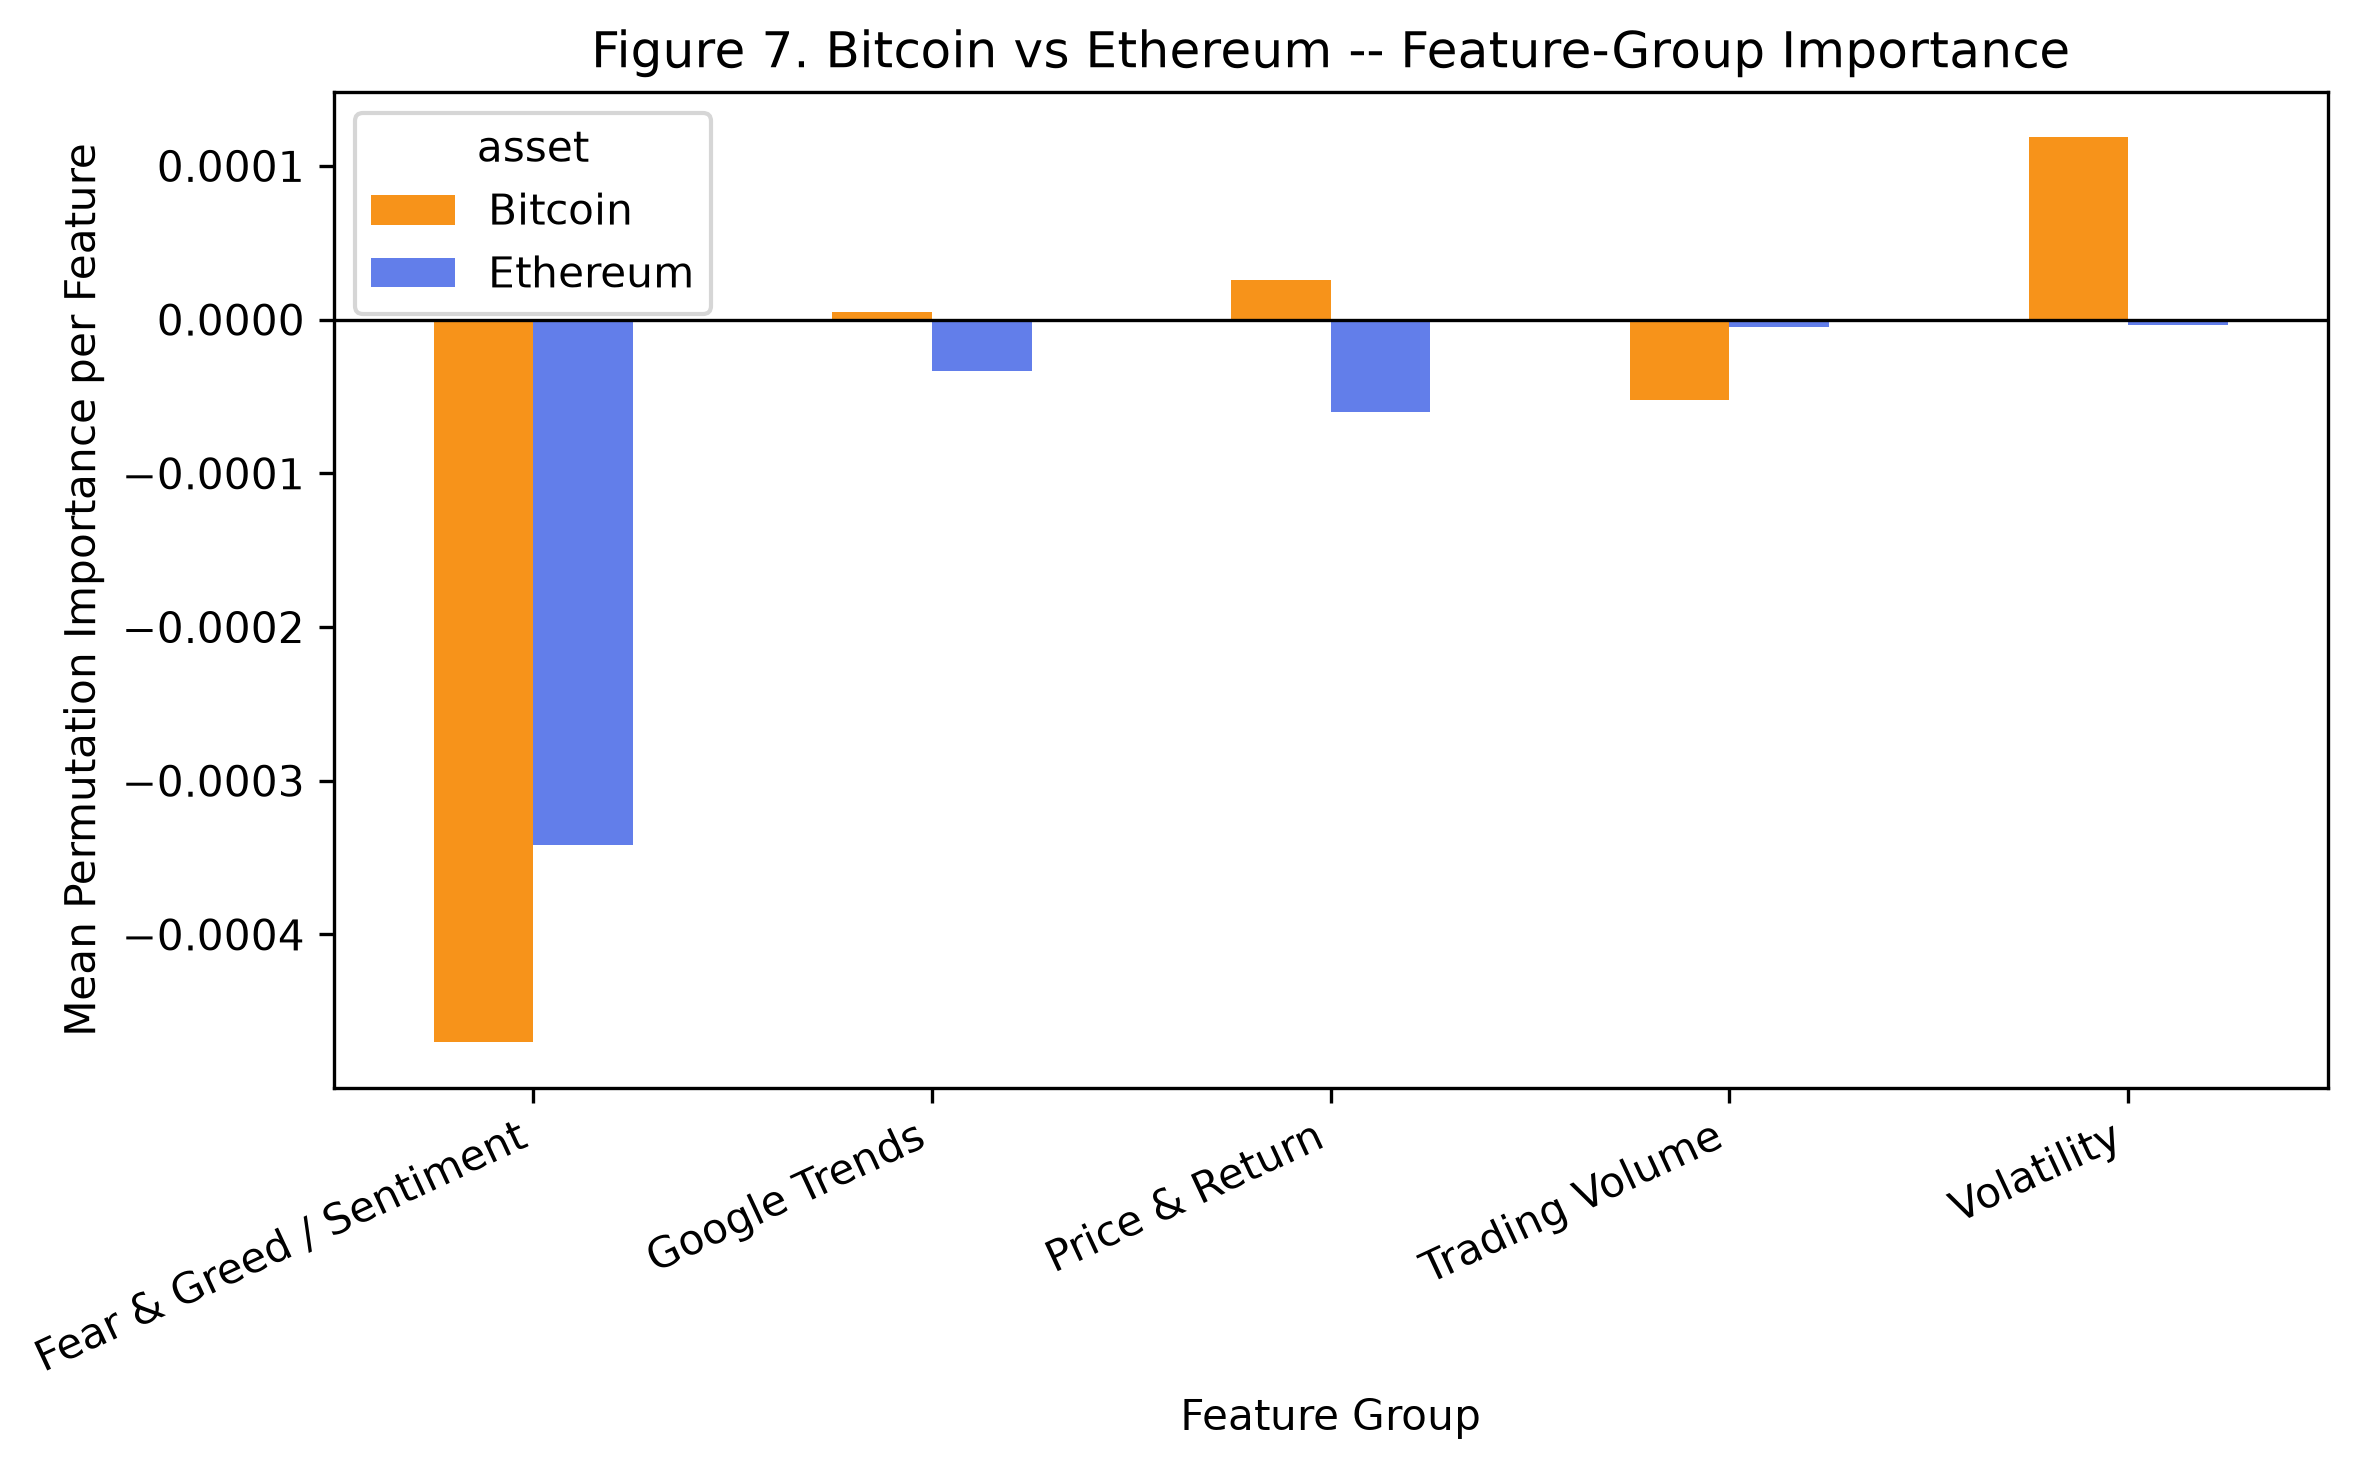

In [11]:
asset_group = group_df.groupby(["asset", "feature_group"])["mean_importance"].mean().reset_index()
pivot = asset_group.pivot(index="feature_group", columns="asset", values="mean_importance")

fig, ax = plt.subplots(figsize=(8, 5))
pivot.plot(kind="bar", ax=ax, color=["#f7931a", "#627eea"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean Permutation Importance per Feature")
ax.set_xlabel("Feature Group")
ax.set_title("Figure 7. Bitcoin vs Ethereum -- Feature-Group Importance")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
path7 = FIGURES_DIR / "7_btc_vs_eth_comparison.png"
plt.savefig(path7, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(path7)))

## 11. Cross-Model Rank Agreement

How consistently Random Forest and XGBoost rank the same features, per configuration -- Spearman rank correlation and top-5/top-10 overlap. Spearman is skipped for any configuration with fewer than 3 comparable features rather than forcing a number that would not be meaningful.

In [12]:
cross_model = compare_model_rankings(long_df)
cross_model.to_csv(PROCESSED_DIR / "cross_model_comparison.csv", index=False)

rank_agreement = compute_rank_agreement_summary(cross_model)
rank_agreement.to_csv(PROCESSED_DIR / "rank_agreement_summary.csv", index=False)

print(f"Mean Spearman rho across all 24 configurations: {rank_agreement['spearman_rho'].mean():.3f}")
print(f"Mean top-5 overlap: {rank_agreement['top_5_overlap'].mean():.2f} / 5")
print(f"Mean top-10 overlap: {rank_agreement['top_10_overlap'].mean():.2f} / 10")
display(rank_agreement.sort_values("spearman_rho").reset_index(drop=True))

Mean Spearman rho across all 24 configurations: 0.247
Mean top-5 overlap: 1.62 / 5
Mean top-10 overlap: 5.12 / 10


/Users/mas364/Desktop/AI_Crypto_Forecasting/src/feature_importance/aggregate.py:81: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pval = spearmanr(both["rank_Random Forest"], both["rank_XGBoost"])


,asset,horizon,feature_set_key,representation,n_features_compared,spearman_rho,spearman_pvalue,top_5_overlap,top_10_overlap
0,Ethereum,7,ablation,Original,21,-0.344101,0.126663,1,1
1,Bitcoin,14,primary,Original,15,-0.229660,0.410283,0,6
2,Bitcoin,7,primary,Original,15,-0.018185,0.948712,2,6
3,Bitcoin,7,combined,Original,25,0.031795,0.880077,2,3
4,Ethereum,14,primary,Original,15,0.075292,0.789711,1,6
5,Bitcoin,1,combined,Original,24,0.077662,0.718324,0,2
6,Ethereum,1,combined,Original,24,0.083210,0.699086,1,5
7,Ethereum,7,primary,Original,15,0.169589,0.545685,1,7
8,Bitcoin,14,ablation,Original,21,0.186989,0.417010,2,5
9,Bitcoin,14,candidate,Original,19,0.263675,0.275382,0,4


**Interpretation.** Agreement is real but modest -- averaging around 0.25 rank correlation, well short of the two models picking near-identical rankings. This is a genuine finding, not a problem to explain away: Random Forest and XGBoost are regularized differently and can lean on different members of a correlated feature cluster while reaching similar overall accuracy, which shows up as low individual-feature rank agreement even when both models are capturing similar aggregate signal.

## 12. Comparison with Correlation and Granger Causality

Cross-referencing permutation importance against this project's existing correlation and Granger causality results (Notebook 05) -- reusing the same asset-aware, method-aware matching already built and verified earlier in this project's development, not a separate implementation.

Permutation importance measures how much a fitted model's predictions depend on a feature. Correlation measures linear association. Granger causality measures whether past values of one series carry incremental predictive information about another under the tested lag structure. None of the three implies the others, and none of them establishes that one variable causes another -- results are described as "associated with" or "showed predictive importance," never as causal.

In [13]:
with_evidence = merge_with_statistical_evidence(long_df)
with_evidence.to_csv(PROCESSED_DIR / "statistical_evidence.csv", index=False)

top_by_importance = with_evidence.sort_values("mean_importance", ascending=False).head(10)
display(top_by_importance[["asset", "feature", "matched_variable", "correlation_r", "granger_significant", "mean_importance"]].reset_index(drop=True))

,asset,feature,matched_variable,correlation_r,granger_significant,mean_importance
0,Bitcoin,Bitcoin_Price_log_return_rolling_std_30,Bitcoin_Price,NaN,None,0.002045
1,Bitcoin,Bitcoin_Price_log_return_rolling_mean_30,Bitcoin_Price,NaN,None,0.001496
2,Ethereum,Ethereum_Price_log_return_rolling_std_30,Ethereum_Price,NaN,None,0.000995
3,Bitcoin,Bitcoin_Price_log_return_rolling_mean_30,Bitcoin_Price,NaN,None,0.000778
4,Ethereum,Ethereum_Volume_rolling_std_30,Ethereum_Volume,-0.035612,None,0.000725
5,Bitcoin,Bitcoin_Price_log_return_rolling_std_30,Bitcoin_Price,NaN,None,0.000634
6,Bitcoin,Bitcoin_Price_log_return_rolling_mean_30,Bitcoin_Price,NaN,None,0.000603
7,Bitcoin,Bitcoin_Price_log_return_rolling_mean_30,Bitcoin_Price,NaN,None,0.000514
8,Ethereum,Ethereum_Volume_rolling_std_30,Ethereum_Volume,-0.035612,None,0.000490
9,Bitcoin,Bitcoin_Price_log_return_rolling_std_30,Bitcoin_Price,NaN,None,0.000482


**Interpretation.** The features with the highest permutation importance are mostly self-referential (a feature matched to the asset's own price series has no separate correlation value to compare against by construction, since a variable cannot be meaningfully correlated with itself). Where an external variable is matched, its correlation coefficient is consistently weak, in line with this project's existing correlation and Granger findings for Google Trends and Fear & Greed -- the ML-importance results here do not contradict that earlier finding.

## 13. Conclusions

Random Forest and XGBoost agree on the broad shape of what matters -- price-return and volume features dominate, external variables contribute little -- but agree only modestly on the precise ranking of individual features (mean Spearman rho around 0.25). Volatility is the one feature group with a consistently positive contribution across every asset, horizon, and configuration tested. Fear & Greed / Sentiment is the most consistently negative group, and becomes more negative at longer horizons rather than more useful, which does not support a hypothesis that sentiment becomes more informative further out. These findings do not conflict with this project's existing correlation and Granger causality results; they add a model-dependent, predictive-performance-based perspective alongside the purely statistical one already in the dissertation.

Every result in this notebook was computed directly from this project's real trained models and real chronological test data. No feature, configuration, or number here was invented.